In [1]:
from sklearn.gaussian_process import GaussianProcessRegressor, kernels
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

In [2]:
saved_dir = Path('/home/hedi/HSCNG/MFs/mock_results_g')

In [3]:
tomo = 4
MF_name = 'V2'
MF_results = np.load(saved_dir / f'{MF_name}_results_z{tomo}.npy', allow_pickle=True)

In [4]:
x = MF_results[0][0]
s_mean_p = MF_results[:,1]
s_std_p = MF_results[:,2]

# x = x[:13]
# s_mean_p = s_mean_p[:,:13]
# s_std_p = s_std_p[:,:13]

In [5]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)

In [6]:
cosmo_Om = cosmo_pars[:,1]
cosmo_S8 = cosmo_pars[:,3]
cosmo_H0 = cosmo_pars[:,4]

# order of pars: Om, S8, H0

In [7]:
X = np.c_[cosmo_Om, cosmo_S8, cosmo_H0]         # order: Om, S8, H0
mid_val = X.mean(axis=0)

X = X - mid_val
Y = s_mean_p

In [8]:
ranges = np.ptp(X, axis=0)

# Plot one sample

Text(0.5, 1.0, 'V2, z=4\nOm=0.439, S8=0.742, H0=0.679')

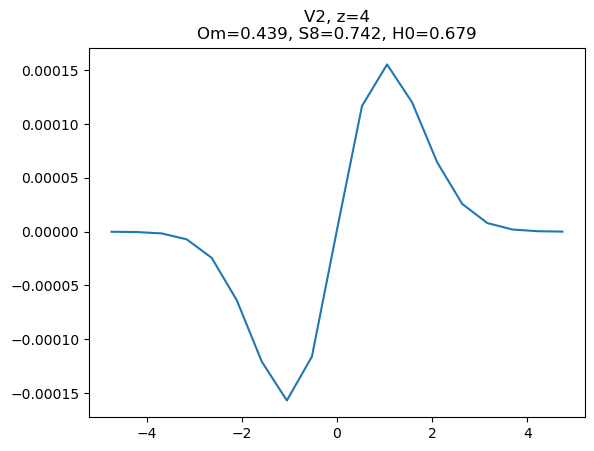

In [153]:
plt.plot(x, Y[30])
plt.title(f"{MF_name}, z={tomo}\nOm={cosmo_Om[30]:.3f}, S8={cosmo_S8[30]:.3f}, H0={cosmo_H0[30]:.3f}")

# Plot par-varied stats

In [9]:
def plot_gpr_lines(x_t, ys, gif_path, interval=120):

    from matplotlib.animation import FuncAnimation, PillowWriter
    from IPython.display import Image, display

    fig, ax = plt.subplots(figsize=(6, 4))
    cmap_anim = plt.get_cmap("viridis")

    ymin, ymax = ys.min(), ys.max()
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(ymin, ymax)

    def update(frame):
        ax.clear()
        ax.set_xlim(x.min(), x.max())
        ax.set_ylim(ymin, ymax)
        for j in range(frame + 1):
            ax.plot(x, ys[j], color=cmap_anim(j / max(1, ys.shape[0] - 1)))
        ax.set_title(f"Curves: {frame + 1}/{ys.shape[0]}\n(Om={x_t[frame][0] + mid_val[0]:.2f}, S8={x_t[frame][1] + mid_val[1]:.2f}, H0={x_t[frame][2] + mid_val[2]:.2f})")
        ax.set_xlabel("x")

    anim = FuncAnimation(fig, update, frames=ys.shape[0], interval=interval, blit=False)

    anim.save(gif_path, writer=PillowWriter(fps=8))
    plt.close(fig)

    display(Image(filename=str(gif_path)))

# simple Matern kernel

In [10]:
gpr = GaussianProcessRegressor(
    kernel=kernels.RBF(length_scale=ranges*2, 
    length_scale_bounds=(1e-2, 1e4)),
    # kernel=kernels.Matern(length_scale=ranges*2, nu=2.5),
    alpha=1e-6, normalize_y=True,
    n_restarts_optimizer=10,
    random_state=139
)

gpr.fit(X, Y).kernel_

RBF(length_scale=[0.0453, 0.0878, 0.163])

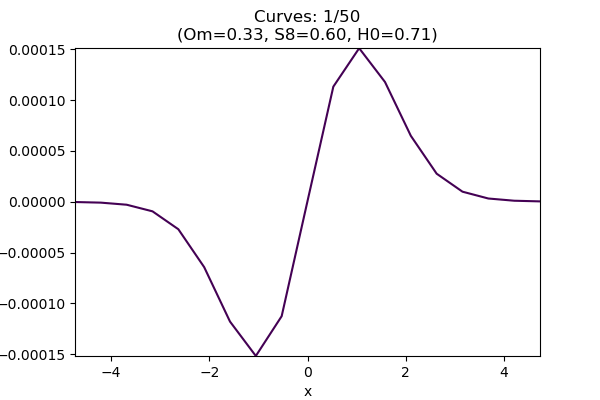

In [12]:
h_t = 0
om_t = 0
s_t = np.linspace(-0.15, 0.15, 50)
x_t = np.c_[om_t*np.ones_like(s_t), s_t, h_t*np.ones_like(s_t)]

ys = gpr.predict(x_t)
gif_path = saved_dir / f"{MF_name}/{MF_name}_inc_s8_z{tomo}.gif"

plot_gpr_lines(x_t, ys, gif_path)

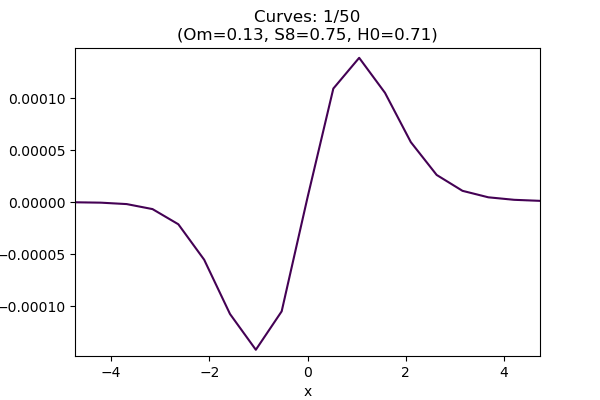

In [13]:
h_t = 0
om_t = np.linspace(-0.2, 0.2, 50)
s_t = 0
x_t = np.c_[om_t, s_t*np.zeros_like(om_t), h_t*np.ones_like(om_t)]

ys = gpr.predict(x_t)
gif_path = saved_dir / f"{MF_name}/{MF_name}_inc_om_z{tomo}.gif"

plot_gpr_lines(x_t, ys, gif_path)

H0 doesn't really matter

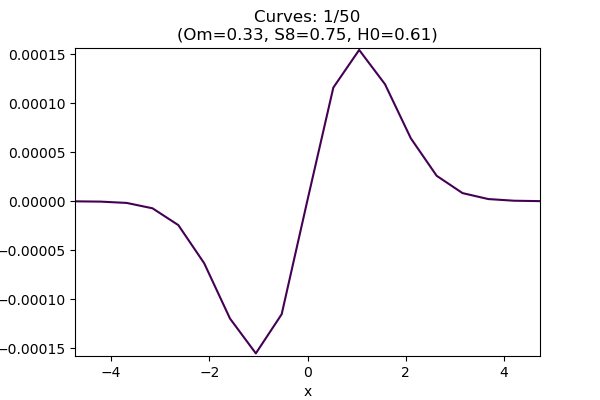

In [158]:
h_t = np.linspace(-0.1, 0.1, 50)
om_t = 0
s_t = 0
x_t = np.c_[om_t*np.ones_like(h_t), s_t*np.zeros_like(h_t), h_t]

ys = gpr.predict(x_t)
gif_path = saved_dir / f"{MF_name}/{MF_name}_inc_h0_z{tomo}.gif"

plot_gpr_lines(x_t, ys, gif_path)

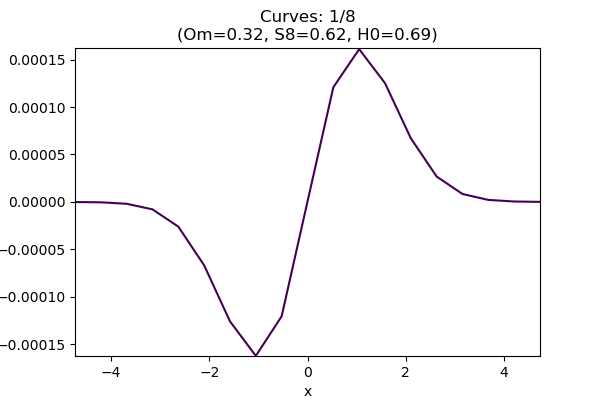

In [159]:
index = (X[:,0] < 0.05) & (X[:,0] > -0.05) & (X[:,2] < 0.05) & (X[:,2] > -0.05)         # controls Om and H0
S_plot = X[index, 1]
Y_plot = Y[index]
sort_index = np.argsort(S_plot)

X_plot = X[index][sort_index]
Y_plot = Y[index][sort_index]
plot_gpr_lines(X_plot, Y_plot, saved_dir / f"{MF_name}/{MF_name}_real_s8_z{tomo}.gif", interval=800)

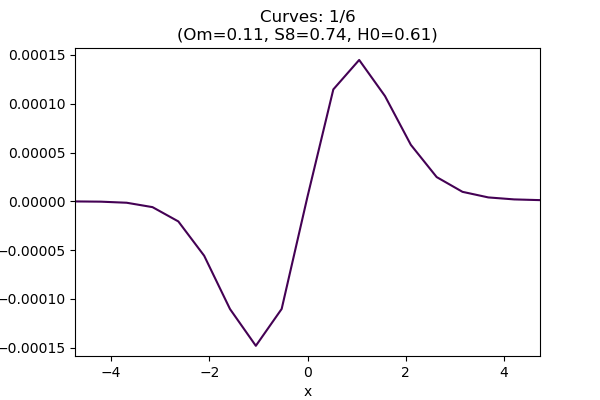

In [160]:
index = (X[:,1] < 0.02) & (X[:,1] > -0.02) & (X[:,2] < 0.2) & (X[:,2] > -0.2)       # controls S8 and H0
Om_plot = X[index, 0]
Y_plot = Y[index]
sort_index = np.argsort(Om_plot)

X_plot = X[index][sort_index]
Y_plot = Y[index][sort_index]
plot_gpr_lines(X_plot, Y_plot, saved_dir / f"{MF_name}/{MF_name}_real_Om0_z{tomo}.gif", interval=800)

# take one out
Estimator:
$$
\sqrt{\frac{1}{N} \sum \left(\frac{y^i-y_{pre}^i}{\sigma^i}\right)^2}
$$

In [161]:
def takeout_test(takeout_index, print_kernel=False, **kwargs):
    select = np.arange(len(X)) != takeout_index
    X_train = X[select]
    Y_train = Y[select]

    X_test = X[takeout_index]
    Y_test = Y[takeout_index]
    sig_test = s_std_p[takeout_index]

    default_kwargs = {
        'kernel': kernels.RBF(length_scale=ranges, 
        length_scale_bounds=(1e-2, 1e2)),       # be careful if the optimizer is going to push it to the boundary
        'alpha': 1e-6, 'normalize_y': True,
        'n_restarts_optimizer': 50,
        'random_state': 139
    }
    default_kwargs.update(kwargs)
    gpr = GaussianProcessRegressor(
        **default_kwargs
    )

    gpr.fit(X_train, Y_train).kernel_

    Y_pre = gpr.predict(X_test.reshape(1, -1))

    res = (Y_test - Y_pre) / sig_test
    res = res[np.isnan(res) == False]       # this happens at 0/0

    if print_kernel:
        print(gpr.kernel_)

    return np.sqrt((res**2).mean())

In [162]:
rmse = []
for i in range(len(X)):
    rmse.append(takeout_test(i, kernel=kernels.Matern(length_scale=ranges*2, nu=2.5)))

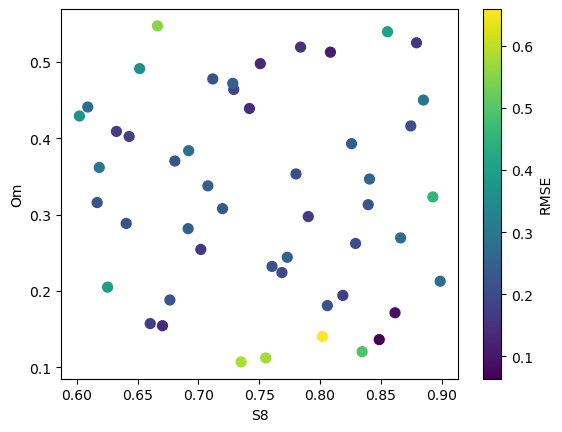

In [163]:
plt.scatter(cosmo_S8, cosmo_Om, c=rmse, cmap='viridis', s=50)
plt.colorbar(label='RMSE')
plt.xlabel('S8')
plt.ylabel('Om')
plt.savefig(saved_dir / f"{MF_name}/{MF_name}_rmse_z{tomo}.png", dpi=300)

# try some new kernels

## RBF + const * expsinsquare

In [ ]:
kernel = kernels.RBF(length_scale=ranges, length_scale_bounds=(1e-2, 1e2))  + \
    kernels.ExpSineSquared(length_scale=1.0, periodicity=1.0, length_scale_bounds=(1e-2, 1e2), periodicity_bounds=(1e-2, 1e2)) \
        * kernels.ConstantKernel(constant_value=1.0, constant_value_bounds=(1e-4, 1e2))
# this kernel seems not stable.

gpr = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=True,
    n_restarts_optimizer=100,
    random_state=70
)


gpr.fit(X, Y).kernel_

/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k1__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RBF(length_scale=[0.147, 0.194, 0.633]) + ExpSineSquared(length_scale=0.01, periodicity=0.01) * 0.158**2

In [93]:
rmse = []
for i in range(len(X)):
    rmse.append(takeout_test(i, print_kernel=True, kernel=kernel, alpha=1e-10))

RBF(length_scale=[0.148, 0.196, 0.649]) + ExpSineSquared(length_scale=0.0142, periodicity=3.6) * 0.158**2
RBF(length_scale=[0.145, 0.194, 0.627]) + ExpSineSquared(length_scale=0.0189, periodicity=2.74) * 0.157**2
RBF(length_scale=[0.147, 0.194, 0.662]) + ExpSineSquared(length_scale=0.0513, periodicity=1) * 0.157**2


/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k1__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RBF(length_scale=[0.162, 0.163, 1.27]) + ExpSineSquared(length_scale=0.01, periodicity=0.439) * 0.161**2
RBF(length_scale=[0.145, 0.195, 0.619]) + ExpSineSquared(length_scale=0.0193, periodicity=0.487) * 0.159**2


/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k1__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RBF(length_scale=[0.148, 0.199, 0.628]) + ExpSineSquared(length_scale=0.01, periodicity=0.01) * 0.158**2
RBF(length_scale=[0.147, 0.196, 0.626]) + ExpSineSquared(length_scale=0.017, periodicity=1.58) * 0.156**2
RBF(length_scale=[0.147, 0.195, 0.654]) + ExpSineSquared(length_scale=0.139, periodicity=0.499) * 0.159**2
RBF(length_scale=[0.148, 0.196, 0.614]) + ExpSineSquared(length_scale=0.0398, periodicity=1.33) * 0.155**2


/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k1__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


... (19 outputs left out)

/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 3763 iteration(s) (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


RBF(length_scale=[0.148, 0.195, 0.644]) + ExpSineSquared(length_scale=0.0171, periodicity=1.74) * 0.159**2
RBF(length_scale=[0.148, 0.194, 0.625]) + ExpSineSquared(length_scale=0.013, periodicity=0.457) * 0.155**2
RBF(length_scale=[0.148, 0.197, 0.627]) + ExpSineSquared(length_scale=0.0206, periodicity=0.487) * 0.157**2
RBF(length_scale=[0.149, 0.196, 0.643]) + ExpSineSquared(length_scale=0.0132, periodicity=0.47) * 0.157**2
RBF(length_scale=[0.15, 0.197, 0.631]) + ExpSineSquared(length_scale=0.0171, periodicity=1.74) * 0.157**2
RBF(length_scale=[0.149, 0.198, 0.614]) + ExpSineSquared(length_scale=0.0198, periodicity=0.487) * 0.157**2


/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k1__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RBF(length_scale=[0.148, 0.197, 0.623]) + ExpSineSquared(length_scale=0.01, periodicity=0.0153) * 0.156**2
RBF(length_scale=[0.145, 0.184, 0.651]) + ExpSineSquared(length_scale=0.0171, periodicity=1.74) * 0.15**2
RBF(length_scale=[0.148, 0.195, 0.643]) + ExpSineSquared(length_scale=0.0395, periodicity=1.31) * 0.158**2
RBF(length_scale=[0.146, 0.192, 0.655]) + ExpSineSquared(length_scale=0.0209, periodicity=0.454) * 0.156**2
RBF(length_scale=[0.151, 0.192, 0.61]) + ExpSineSquared(length_scale=0.0812, periodicity=0.685) * 0.156**2
RBF(length_scale=[0.147, 0.195, 0.646]) + ExpSineSquared(length_scale=0.0455, periodicity=1.21) * 0.159**2
RBF(length_scale=[0.147, 0.193, 0.62]) + ExpSineSquared(length_scale=0.0534, periodicity=0.927) * 0.158**2
RBF(length_scale=[0.148, 0.195, 0.643]) + ExpSineSquared(length_scale=0.0719, periodicity=0.71) * 0.158**2
RBF(length_scale=[0.148, 0.195, 0.645]) + ExpSineSquared(length_scale=0.0311, periodicity=1.65) * 0.157**2
RBF(length_scale=[0.147, 0.194, 0.638

Text(0, 0.5, 'Om')

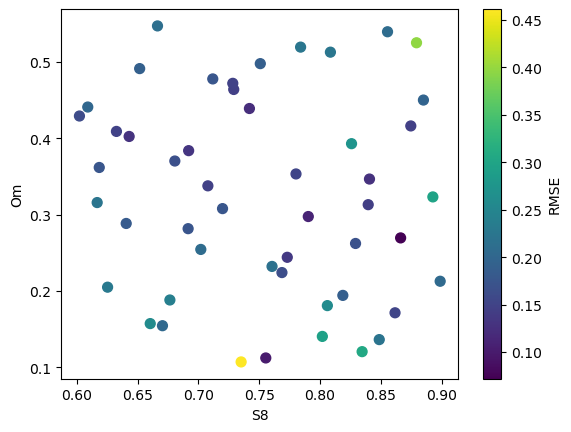

In [95]:
plt.scatter(cosmo_S8, cosmo_Om, c=rmse, cmap='viridis', s=50)
plt.colorbar(label='RMSE')
plt.xlabel('S8')
plt.ylabel('Om')

## matern + const * dot

In [96]:
kernel = kernels.Matern(length_scale=ranges, length_scale_bounds=(1e-2, 1e2), nu=2.5) + \
    kernels.ConstantKernel(constant_value=1.0, constant_value_bounds=(1e-4, 1e2)) * \
    kernels.DotProduct(sigma_0=1.0, sigma_0_bounds=(1e-8, 1e2))

In [86]:
rmse = []
for i in range(len(X)):
    rmse.append(takeout_test(i, print_kernel=True, kernel=kernel, alpha=1e-6))

Matern(length_scale=[0.122, 0.34, 0.111], nu=2.5) + 6.24**2 * DotProduct(sigma_0=0.0349)
Matern(length_scale=[0.128, 0.303, 0.112], nu=2.5) + 6.43**2 * DotProduct(sigma_0=6.75e-08)
Matern(length_scale=[0.126, 0.313, 0.11], nu=2.5) + 6.26**2 * DotProduct(sigma_0=0.0265)
Matern(length_scale=[0.13, 0.308, 0.107], nu=2.5) + 6.32**2 * DotProduct(sigma_0=0.0399)
Matern(length_scale=[0.127, 0.297, 0.112], nu=2.5) + 6.3**2 * DotProduct(sigma_0=1.59e-08)
Matern(length_scale=[0.13, 0.314, 0.105], nu=2.5) + 6.27**2 * DotProduct(sigma_0=0.0201)
Matern(length_scale=[0.129, 0.301, 0.11], nu=2.5) + 6.22**2 * DotProduct(sigma_0=0.0222)
Matern(length_scale=[0.133, 0.295, 0.109], nu=2.5) + 6.12**2 * DotProduct(sigma_0=1.78e-08)
Matern(length_scale=[0.128, 0.311, 0.111], nu=2.5) + 6.22**2 * DotProduct(sigma_0=0.0296)
Matern(length_scale=[0.128, 0.304, 0.113], nu=2.5) + 6.19**2 * DotProduct(sigma_0=0.032)
Matern(length_scale=[0.128, 0.299, 0.109], nu=2.5) + 6.31**2 * DotProduct(sigma_0=0.00469)
Matern(len

/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 25 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


Matern(length_scale=[0.126, 0.314, 0.107], nu=2.5) + 6.36**2 * DotProduct(sigma_0=1.05e-08)
Matern(length_scale=[0.129, 0.308, 0.111], nu=2.5) + 6.2**2 * DotProduct(sigma_0=0.0199)
Matern(length_scale=[0.13, 0.317, 0.102], nu=2.5) + 6.51**2 * DotProduct(sigma_0=0.0493)
Matern(length_scale=[0.129, 0.313, 0.106], nu=2.5) + 6.26**2 * DotProduct(sigma_0=0.0242)
Matern(length_scale=[0.127, 0.278, 0.116], nu=2.5) + 6.38**2 * DotProduct(sigma_0=0.0299)
Matern(length_scale=[0.124, 0.316, 0.109], nu=2.5) + 6.28**2 * DotProduct(sigma_0=1.17e-07)
Matern(length_scale=[0.126, 0.317, 0.108], nu=2.5) + 6.29**2 * DotProduct(sigma_0=0.0338)
Matern(length_scale=[0.129, 0.323, 0.107], nu=2.5) + 6.43**2 * DotProduct(sigma_0=0.0483)
Matern(length_scale=[0.125, 0.315, 0.116], nu=2.5) + 6.2**2 * DotProduct(sigma_0=0.0263)
Matern(length_scale=[0.13, 0.304, 0.11], nu=2.5) + 6.21**2 * DotProduct(sigma_0=0.0196)
Matern(length_scale=[0.126, 0.304, 0.118], nu=2.5) + 6.18**2 * DotProduct(sigma_0=0.0228)
Matern(leng

/home/hedi/data/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k2__sigma_0 is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Matern(length_scale=[0.13, 0.309, 0.108], nu=2.5) + 6.29**2 * DotProduct(sigma_0=1e-08)
Matern(length_scale=[0.132, 0.307, 0.108], nu=2.5) + 6.2**2 * DotProduct(sigma_0=0.0217)
Matern(length_scale=[0.126, 0.303, 0.109], nu=2.5) + 6.32**2 * DotProduct(sigma_0=2.67e-08)


Text(0, 0.5, 'Om')

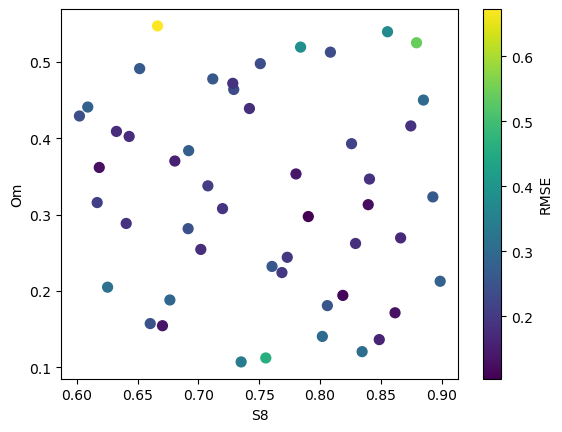

In [87]:
plt.scatter(cosmo_S8, cosmo_Om, c=rmse, cmap='viridis', s=50)
plt.colorbar(label='RMSE')
plt.xlabel('S8')
plt.ylabel('Om')

In [97]:
gpr = GaussianProcessRegressor(
    kernel=kernels.Matern(length_scale=ranges, length_scale_bounds=(1e-2, 1e2), nu=2.5) + \
    kernels.ConstantKernel(constant_value=1.0, constant_value_bounds=(1e-4, 1e2)) * \
    kernels.DotProduct(sigma_0=1.0, sigma_0_bounds=(1e-8, 1e2)),
    normalize_y=True,
    n_restarts_optimizer=100,
    random_state=70
)

gpr.fit(X, Y).kernel_

Matern(length_scale=[0.128, 0.309, 0.109], nu=2.5) + 6.26**2 * DotProduct(sigma_0=0.0244)

In [100]:
mid_val

array([0.3256002, 0.7516824, 0.709174 ])

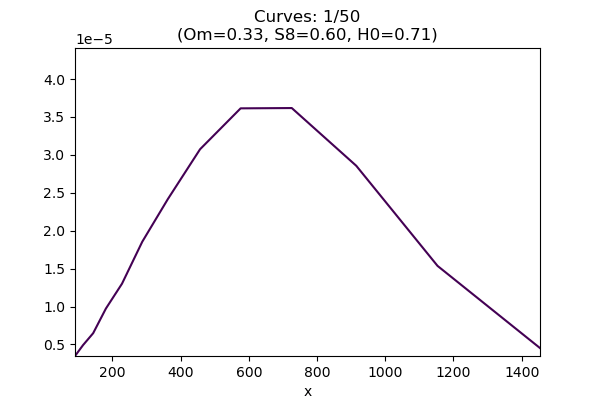

In [98]:
h_t = 0
om_t = 0
s_t = np.linspace(-0.15, 0.15, 50)
x_t = np.c_[om_t*np.ones_like(s_t), s_t, h_t*np.ones_like(s_t)]

ys = gpr.predict(x_t)
gif_path = saved_dir / f"inc_s8_z{tomo}_v2.gif"

plot_gpr_lines(x_t, ys, gif_path)

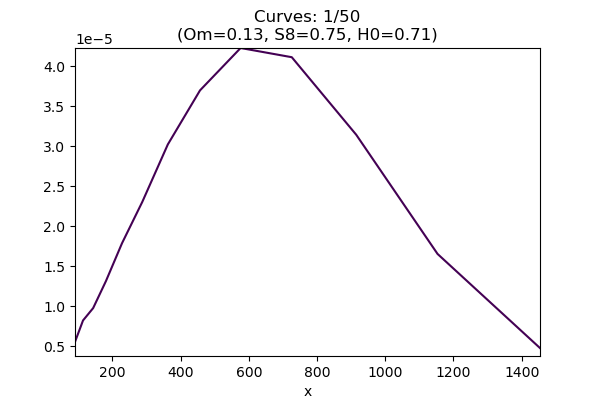

In [102]:
h_t = 0
om_t = np.linspace(-0.2, 0.2, 50)
s_t = 0
x_t = np.c_[om_t, s_t*np.zeros_like(om_t), h_t*np.ones_like(om_t)]

ys = gpr.predict(x_t)
gif_path = saved_dir / f"inc_om_z{tomo}_v2.gif"

plot_gpr_lines(x_t, ys, gif_path)